# Search a Trade Space

This example demonstrates how to search a trade space of constellation designs for Pareto-efficient designs with the `tatc.tradespace` module: declaring a hierarchical design space, evaluating designs in replicates (in parallel, with a cache of the analysis of each satellite), ranking them with the uncertainty of their replicates, screening them with a cheaper analysis, and searching the space with optimizers (Optuna and pymoo, installed with `pip install tatc[tradespace]`).

The trade is a sampling problem of a pre-Phase A study: how many satellites, in how many orbit planes (each of which needs its own launch), sample the Earth sufficiently often? A point is **sufficiently sampled** if an imager observes it at least four times in a day, and the objective is the share of points that are. A second objective measures sufficiency by its purpose: a point is **accurately sampled** if the mean of its samples estimates the daily mean of a field that varies within hours (such as convective precipitation) with an error of at most half the field's standard deviation. The points are a random sample of the Earth (a lattice of points in a random orientation), so the share is a statistical estimate: each replicate of a design draws a different sample of points, which is the uncertainty of the estimate.

## Configure the Analysis

The analysis covers one day, with 100 points in each of five replicates. A design may have at most 10 satellites.

In [1]:
from datetime import datetime, time as time_of_day, timedelta, timezone
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

START = datetime(2026, 7, 1, tzinfo=timezone.utc)
DURATION = timedelta(days=1)  # the period of the analysis
N_POINTS = 100  # points sampled in each replicate
N_REPLICATES = 5  # replicates (samples of points) of each design
SAMPLES_PER_DAY = 4  # a point is sufficiently sampled if it is observed at least this often
MAX_SATELLITES = 10
DECORRELATION_TIME = timedelta(hours=3)  # of the field whose daily mean is estimated
MAX_RELATIVE_ERROR = 0.5  # a point is accurately sampled within this share of the field's standard deviation

## Define the Design Space

A `DesignSpace` declares the design variables, in the order they are decided. Every design has an altitude and an imager's field of regard, and a layout that is one of two alternatives (a `Choice`), each declared with a building block of the `tatc.tradespace` module:

* a **Walker delta** constellation (`walker_space`), with an inclination, a number of planes, a number of satellites in each plane, and the relative spacing of the satellites between planes (whose upper bound depends on the number of planes), or
* one or two **sun-synchronous** planes (`sso_planes_space`, a `Repeat` of planes), each with its own equator crossing time and number of satellites. The planes are unordered: two planes in either order are the same design. A constraint of the building block requires the planes to have different crossing times (otherwise, they would be the same plane).

The points sampled in each replicate are an `Uncertain` parameter (the seed of a random orientation of a lattice of points, `Uncertain.seed`), drawn for each replicate rather than designed, as are the failures of satellites and the growth of the cost of developing the satellites (both used below). The replicates use common random numbers: every design samples the same points in the same replicate, so that differences between designs are not differences between their samples. The points of a replicate are a Fibonacci lattice in a random orientation (`generate_points_rotated_lattice`): each point is as likely to fall anywhere as a random point, but the points cover the Earth evenly rather than clustering by chance, so that the shares of points vary less between replicates than with random points (`generate_points_random`; here, with 1.5 to 4 times less variance), and fewer replicates estimate them as precisely. The decorrelation time of the field whose daily mean is estimated is a `Fixed` value of the design space, which the metrics read from each design, rather than a constant of the metrics, so that scenarios can change it (see below).

The constraint on the number of satellites returns the number in excess of the limit (a number that is not positive if the design satisfies it), rather than `True` or `False`, so that optimizers can tell how far an infeasible design is from a feasible one.

In [2]:
from tatc.tradespace import (
    Categorical,
    Choice,
    DesignSpace,
    Fixed,
    Integer,
    Real,
    Uncertain,
    count_satellites,
    sso_planes_space,
    walker_space,
)

space = DesignSpace(
    altitude=Real(500e3, 800e3, step=100e3),
    field_of_regard=Categorical([30, 60]),
    layout=Choice(
        walker=walker_space(inclination=Real(45, 75, step=15), planes=Integer(1, 4), per_plane=Integer(1, 4)),
        sso=sso_planes_space(crossing=Real(6, 18, step=3), satellites=Integer(1, 2), count=Integer(1, 2)),
    ),
    points_seed=Uncertain.seed(),
    failure_seed=Uncertain.seed(),
    cost_growth=Uncertain(lambda rng: float(rng.triangular(0.9, 1.0, 1.6))),  # of development, for cost risk
    decorrelation_time=Fixed(DECORRELATION_TIME),  # of the field, which scenarios may change (see below)
    epoch=Fixed(START),  # the start of the analysis, which may be drawn for each replicate (see below)
    constraints=[lambda d: count_satellites(d.layout) - MAX_SATELLITES],
)
designs = space.enumerate()
print(f"{len(designs)} feasible designs of {len(space.unit_paths())} decisions")

1096 feasible designs of 12 decisions


## Define the Study

An `ObservationStudy` evaluates each design in each replicate: it builds the design's satellites (`build`, with `build_constellation`, which builds the satellites of either layout with a payload: here, an imager, but also entries of the instrument catalog), collects their observations of the replicate's targets (`Observations`), and computes the metrics of the observations (`sample`). The targets are the points of a randomly oriented lattice, generated in each replicate from its seed (`Targets`, from the design's uncertain `points_seed`). The observations of each satellite are cached on disk: designs share many satellites (the same orbit and imager, if not the same name), whose observations are computed once, by the parallel worker processes of the study (`n_jobs=-1`, one per processor), and kept between sessions. A `ResultStore` keeps the records of the evaluations in a file, so that running the notebook again (or resuming it after an interruption) takes them from the file rather than evaluating them again. Both are keyed by the definition of the study (its fingerprint), which describes the points by the recipe that generates them and the code of TAT-C that the study uses: a changed study evaluates its designs again, and says why. The kinds of studies below share the file, each in its own namespace.

The metrics are the two objectives: the share of points with at least four samples a day, and the share whose sampling error (`tatc.analysis.estimate_sampling_error`, for an exponential correlation in time with a decorrelation time of 3 hours) is at most half the field's standard deviation. The study also records the numbers of satellites and of orbit planes (of the design's `layout`), and plans the deployment of each design and estimates its life-cycle cost (`MissionPlan`, of a `DeploymentSchedule` and a `CostModel`, used below).

`make_study` makes studies of other durations and numbers of replicates, of the phases of deployment, and with failures, as for screening, deployment, and robustness (below).

In [3]:
from functools import partial

from tatc.analysis import estimate_sampling_error
from tatc.generation import generate_points_rotated_lattice
from tatc.schemas import Instrument
from tatc.tradespace import (
    CostModel,
    DeploymentSchedule,
    LaunchCost,
    MissionPlan,
    ObservationStudy,
    Observations,
    OperationsCost,
    Requirement,
    ResultStore,
    SatelliteCost,
    Targets,
    build_constellation,
)

# the deployment of each design: 3 years of development, a production line of 4 satellites a year, launches of up to 3
# satellites at most every half year, and 5 years of operations from the first launch
SCHEDULE = DeploymentSchedule(years=5, development_years=3, production_rate=4, launch_interval=0.5, launch_capacity=3)
# illustrative costs (millions of dollars), not estimates of any mission: satellites with an imager of each field of
# regard, small launchers, and operations, discounted at 3% a year
COST_MODEL = CostModel(
    satellites={
        30: SatelliteCost(development=40, first_unit=12, learning_rate=0.9, mass=60),
        60: SatelliteCost(development=60, first_unit=18, learning_rate=0.9, mass=90),
    },
    launch=LaunchCost(per_launch=8),
    operations=OperationsCost(per_year=3, per_satellite_year=0.5),
    discount_rate=0.03,
)

# the deployment and cost of each design: satellites of the kind of its field of regard, with its growth of
# development costs
PLAN = MissionPlan(SCHEDULE, COST_MODEL, kind="field_of_regard", growth={"development": "cost_growth"})
# the points of each replicate: a randomly oriented lattice, generated from the replicate's seed
TARGETS = Targets(generate_points_rotated_lattice, N_POINTS, seed="points_seed")
CACHE_DIRECTORY = Path(tempfile.gettempdir()) / "tatc-search-trade-space"


def sample(observations, design, duration=DURATION):
    """The shares (%) of points sampled sufficiently and accurately by observations over a duration from the design's
    epoch (of the field of the design's decorrelation time)."""
    if len(observations) == 0:  # no satellites
        return {"sufficient": 0.0, "accurate": 0.0}
    samples = observations.groupby("target_hash").size()
    error = estimate_sampling_error(observations, design.epoch, design.epoch + duration, design.decorrelation_time)
    threshold = SAMPLES_PER_DAY * duration / timedelta(days=1)
    return {
        "sufficient": 100 * (samples >= threshold).sum() / N_POINTS,
        "accurate": 100 * (error.relative_error <= MAX_RELATIVE_ERROR).sum() / N_POINTS,
    }


def build(d):
    """The satellites of a design: an imager of its field of regard in each orbit of its layout."""
    imager = Instrument(name="imager", field_of_regard=d.field_of_regard)
    return build_constellation(d.layout, imager, epoch=START, altitude=d.altitude)


def make_study(
    duration=DURATION,
    replicates=N_REPLICATES,
    failures=None,
    phased=False,
    design_space=None,
    scenarios=None,
    plan=PLAN,
    label=None,
):
    """A study of the shares (%) of points sampled sufficiently and accurately over a duration by the satellites of
    each design (of the design space, or another), and of its cost (by the mission plan), and (if phased) their means
    over the phases of the mission as the satellites are deployed and the time until half of the points are sampled
    sufficiently, or (with failures) their summaries over histories of the mission in which satellites fail (see
    Failures), in scenarios, if any. Studies of other design spaces or plans are stored apart, by a label."""
    kind = ("failures" if failures else "phases" if phased else "observations") + (f" {label}" if label else "")
    return ObservationStudy(
        design_space or space,
        build,
        Observations(TARGETS, "epoch", duration, directory=CACHE_DIRECTORY),
        partial(sample, duration=duration),
        layout="layout",
        plan=plan,
        failures=failures,
        phases=[Requirement("sufficient", ">=", 50)] if phased else None,
        replicates=replicates,
        scenarios=scenarios,
        n_jobs=-1,
        store=ResultStore(CACHE_DIRECTORY / "results.sqlite", namespace=f"{kind} over {duration}"),
    )


OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient": "max"}
REFERENCE = {"satellites": MAX_SATELLITES + 1, "planes": 5, "sufficient": 0}  # worse than every design, for hypervolumes

## Evaluate Every Design

The design space is small enough to evaluate every design, which gives the true Pareto front against which the screening and the searches below are compared. `summarize` gives the mean of each objective over the replicates (and its standard deviation and standard error), and `pareto_front` the designs that no other design is as good as in every objective and better than in one.

In [4]:
from tatc.tradespace import hypervolume, pareto_front, summarize

results = make_study().run(designs)
print(f"{len(results)} evaluations: {len(designs)} designs x {N_REPLICATES} replicates")

# the values of each design, and the means of its objectives over the replicates
values = results.drop_duplicates("design").set_index("design").drop(
    columns=["replicate", "points_seed", "failure_seed", "cost_growth", "seconds", "sufficient", "accurate", "feasible"]
)
values = values.drop(columns=[column for column in values.columns if column.startswith("cost")])
summary = summarize(results, list(OBJECTIVES), design_columns=[])
summary["pareto"] = pareto_front(summary, OBJECTIVES)
exact_hypervolume = hypervolume(summary, OBJECTIVES, REFERENCE)


def describe(d):
    """A short description of a design."""
    if d.layout == "walker":
        layout = (
            f"Walker {d['layout.walker.inclination']:.0f} deg: {d['layout.walker.planes']:.0f} x "
            f"{d['layout.walker.per_plane']:.0f} (spacing {d['layout.walker.relative_spacing']:.0f})"
        )
    else:
        planes = [
            f"{d[f'layout.sso.planes[{k}].satellites']:.0f} at {d[f'layout.sso.planes[{k}].crossing']:02.0f}:00"
            for k in range(int(d['layout.sso.planes.count']))
        ]
        layout = "SSO: " + ", ".join(planes)
    return f"{d.altitude / 1e3:.0f} km, {d.field_of_regard} deg FOR, {layout}"


summary["description"] = [describe(values.loc[key]) for key in summary.design]
front = summary[summary.pareto].sort_values(["satellites", "planes"])
front[["description", "satellites", "planes", "sufficient", "sufficient sem"]].round(1)

5480 evaluations: 1096 designs x 5 replicates


,description,satellites,planes,sufficient,sufficient sem
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,0.9
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.6,1.2
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,2.2
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.0,1.2
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,68.2,1.8
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,69.6,0.8
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.8,0.2


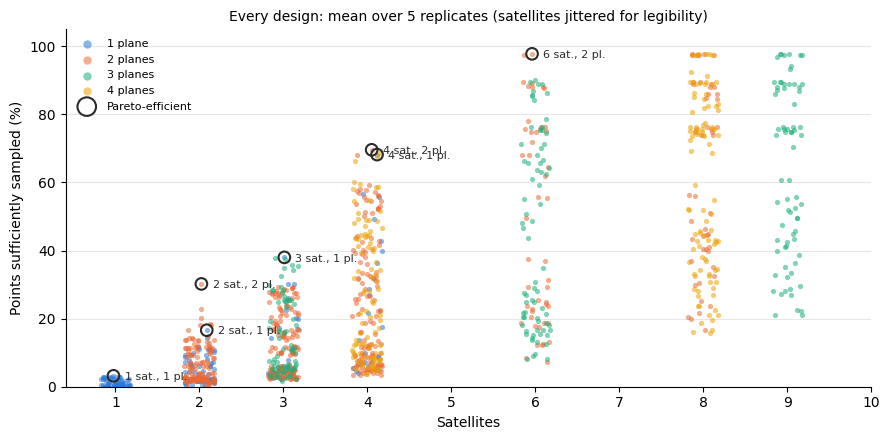

In [5]:
from tatc.tradespace import plot_designs


def planes_name(planes):
    """The name of a number of planes."""
    return f"{planes:.0f} plane{'s' if planes > 1 else ''}"


ax = plot_designs(
    summary,
    "satellites",
    "sufficient",
    by="planes",
    front="pareto",
    labels=lambda row: f"{row.satellites:.0f} sat., {row.planes:.0f} pl.",
    names=planes_name,
    jitter=0.18,  # satellites, for legibility
    legend="upper left",
)
ax.set(
    xlabel="Satellites",
    ylabel="Points sufficiently sampled (%)",
    xticks=range(1, MAX_SATELLITES + 1),
    ylim=(0, 105),
)
ax.set_title("Every design: mean over 5 replicates (satellites jittered for legibility)", fontsize=10)
ax.figure.tight_layout()
plt.show()

Of the 1,096 feasible designs, seven are Pareto-efficient (ringed in the figure). All of them fly at the highest altitude (800 km) with the wider field of regard (60 degrees), which observe the most points per satellite, so the trade is in the number of satellites and planes. One satellite samples only 3% of the points sufficiently (at least four times a day), and the share rises steeply with the number of satellites: two satellites in two planes (30%) sample nearly twice as many points as two in one plane (17%), four satellites sample about two thirds of the points in one plane or two (68% and 70%), and six satellites in two inclined planes sample 98%. No design with more than six satellites is efficient, because six already sample nearly every point. Designs with the same number of satellites differ widely: their layout (inclination, planes, and phasing) matters as much as their number.

## Measure the Sampling Error

Four samples a day count the same whether they come hours apart or minutes apart, but they do not estimate a daily mean equally well: samples closer together than the field's decorrelation time repeat each other. The share of points accurately sampled measures what the samples are for. The table gives the efficient designs by this objective (with the numbers of satellites and planes, as before), and the figure compares the two objectives for every design.

In [6]:
ACCURACY = {"satellites": "min", "planes": "min", "accurate": "max"}
accuracy = summarize(results, ["satellites", "planes", "sufficient", "accurate"], design_columns=[])
accuracy["description"] = [describe(values.loc[key]) for key in accuracy.design]
accuracy["pareto"] = pareto_front(accuracy, ACCURACY)
accuracy[accuracy.pareto].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient", "accurate", "accurate sem"]
].round(1)

,description,satellites,planes,sufficient,accurate,accurate sem
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,4.2,0.6
1047,"800 km, 60 deg FOR, SSO: 2 at 06:00",2.0,1.0,11.6,10.4,0.9
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,34.2,1.8
1019,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",3.0,1.0,26.2,17.0,1.1
1075,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,28.8,60.6,1.3
1001,"800 km, 60 deg FOR, Walker 60 deg: 3 x 1 (spac...",3.0,3.0,34.2,61.0,3.8
1020,"800 km, 60 deg FOR, Walker 75 deg: 1 x 4 (spac...",4.0,1.0,49.2,28.6,2.1
1081,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,57.6,85.4,0.7
758,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6.0,3.0,89.0,96.4,0.5
1045,"800 km, 60 deg FOR, Walker 75 deg: 4 x 2 (spac...",8.0,4.0,97.8,96.6,0.5


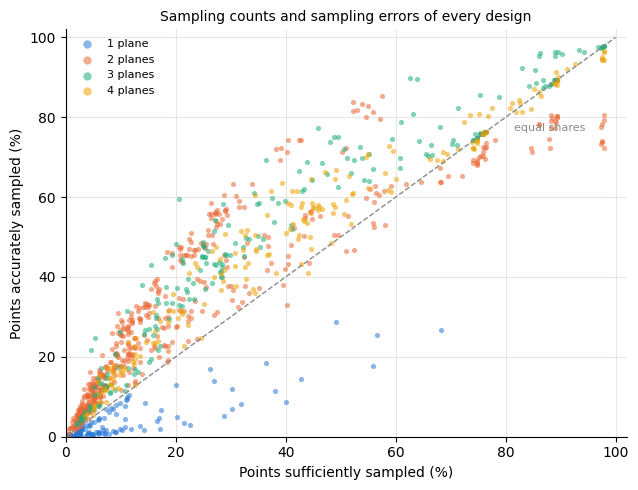

In [7]:
from tatc.tradespace import style_axes
from tatc.tradespace.plotting import GRAY

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_designs(accuracy, "sufficient", "accurate", by="planes", names=planes_name, legend="upper left", ax=ax)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls="--")
ax.annotate("equal shares", (80, 80), xytext=(6, -10), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(xlabel="Points sufficiently sampled (%)", ylabel="Points accurately sampled (%)", xlim=(0, 102), ylim=(0, 102))
style_axes(ax, grid="both")
ax.set_title("Sampling counts and sampling errors of every design", fontsize=10)
fig.tight_layout()
plt.show()

The revisits of two designs of four satellites, those in one plane that sample the most points sufficiently and those that sample the most points accurately, show why they differ in accuracy: the times between their samples (`tatc.analysis.compute_revisit_statistics`), including the longest gap of the day, and the times of day they sample (`tatc.analysis.compute_local_time_coverage`, in eight 3-hour intervals of local time).

In [8]:
from tatc.analysis import compute_local_time_coverage, compute_revisit_statistics

four = accuracy[(accuracy.satellites == 4)].sort_values("sufficient", ascending=False)
# the most sufficiently sampling design of four satellites in one plane, and the most accurately sampling design of four
first = four[four.planes == 1].iloc[0]
second = four.sort_values("accurate", ascending=False).iloc[0]
by_key = {d.key: d for d in designs}
study = make_study()
rows = []
for row in (first, second):
    # the observations of the design's first replicate, and its points
    observations = study.observations_of(by_key[row.design])
    points = study.targets_of(by_key[row.design])
    revisits = compute_revisit_statistics(observations, START, START + DURATION, targets=points)
    local = compute_local_time_coverage(observations, targets=points)
    observed = revisits[revisits.samples > 0]
    rows.append(
        {
            "design": row.description,
            "sufficient (%)": row.sufficient,
            "accurate (%)": row.accurate,
            "median revisit (h)": observed["revisit p50"].dt.total_seconds().median() / 3600,
            "median longest gap (h)": revisits.max_gap.dt.total_seconds().median() / 3600,
            "median 3-h intervals sampled": local.local_bins_sampled.median(),
        }
    )
pd.DataFrame(rows).set_index("design").round(1)

,sufficient (%),accurate (%),median revisit (h),median longest gap (h),median 3-h intervals sampled
design,,,,,
"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spacing 0)",68.2,26.8,0.4,13.8,2.0
"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",57.6,85.4,5.9,7.6,4.0


Counting samples and measuring their sampling error rank designs differently. Satellites in one plane (blue in the figure) sample many points four times a day, but in bursts: consecutive passes of satellites that follow each other in a plane, minutes apart, repeat each other for a field that decorrelates in hours. Four satellites in one Walker plane sample 68% of the points at least four times a day, but only 27% accurately: half of their revisits are 0.4 hours apart, and they leave a gap of 13.8 hours. Four satellites in two sun-synchronous planes sample fewer points four times (58%) but 85% accurately: their samples are 5.9 hours apart, in four of the eight 3-hour intervals of the day. Designs in a single plane remain efficient only as those that need the fewest launches, and sample at most 29% of the points accurately; six satellites in three planes sample 96% of the points accurately, nearly as many as nine (98%).

## Find What Drives the Objectives

`sensitivity` gives the share of the variance of each objective (over the designs, by their means over the replicates) that each design variable explains, among the designs in which the variable is active: the variables of the Walker layout apply only to Walker designs, and those of the sun-synchronous layout only to theirs. The shares are adjusted for the variance that the levels of a variable would explain by chance, which matters for samples of designs and for variables of many levels.

In [9]:
from tatc.tradespace import sensitivity

frame = accuracy.join(values.drop(columns=["satellites", "planes"]), on="design")
variables = [
    "altitude",
    "field_of_regard",
    "layout",
    "layout.walker.inclination",
    "layout.walker.planes",
    "layout.walker.per_plane",
    "layout.walker.relative_spacing",
    "layout.sso.planes.count",
]
sensitivity(frame, variables, ["sufficient", "accurate"]).round(2)

,sufficient,accurate,active
variable,,,
field_of_regard,0.25,0.25,1.00
layout.walker.per_plane,0.22,0.18,0.64
layout,0.19,0.12,1.00
layout.walker.planes,0.12,0.29,0.64
layout.sso.planes.count,0.10,0.19,0.36
altitude,0.03,0.03,1.00
layout.walker.relative_spacing,0.03,0.06,0.64
layout.walker.inclination,0.00,0.00,0.64


The field of regard explains the most of both objectives (25% of their variance), as it sets the swath of every satellite. The layout matters next, but differently for the two objectives: the number of satellites in each Walker plane explains more of the share of points sufficiently sampled (22%) than of those accurately sampled (18%), and the number of Walker planes the reverse (12% and 29%), as more planes spread the samples in time. The altitude explains little of either objective (3%), although a higher orbit widens the swath: its effect is small next to those of the field of regard and the layout. The inclination explains nothing on average over the Walker designs.

## Rank Designs with the Uncertainty of Replicates

The means of five replicates are uncertain, and so is the front of the means: a design just behind another in the means may be ahead of it in other samples of points. `pareto_probability` estimates the probability that each design is efficient by a bootstrap: it resamples the replicates (the same replicates for every design, which keeps the correlation between designs of common random numbers) and counts how often each design is on the front of the resampled means.

In [10]:
from tatc.tradespace import pareto_probability

probability = pareto_probability(results, OBJECTIVES, n_resamples=1000)
probability["description"] = [describe(values.loc[key]) for key in probability.design]
candidates = probability[probability.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])
candidates[["description", "satellites", "planes", "sufficient", "pareto", "pareto_probability"]].round(2)

,description,satellites,planes,sufficient,pareto,pareto_probability
1017,"800 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,2.8,False,0.38
776,"700 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,False,0.20
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,3.0,False,0.12
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,False,0.10
1052,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,3.0,False,0.12
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,True,0.54
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.6,True,0.98
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,True,1.00
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.0,True,1.00
972,"800 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,37.6,False,0.32


Four of the seven efficient designs are efficient in every resample: two satellites in two planes, three or four satellites in one plane, and six in two planes; two satellites in one plane (efficient in 98% of the resamples) and four in two planes (92%) nearly so. The single satellite is not settled by five replicates: one in a sun-synchronous orbit crossing the equator at 18:00 (efficient in 54% of the resamples) samples about as many points as one in a Walker orbit inclined 75 degrees (38%) or crossing at other times (10 to 20%). Likewise, three satellites in three planes (29% and 32%) sample about as many points as three in one plane, and six satellites in two planes with another relative spacing (32%) as many as the efficient design. Designs that are efficient with a probability between 0 and 1 are equally good candidates, given the uncertainty of the estimates: more replicates (samples of points) would separate them, or a tolerance of the share (see `pareto_front`) would treat them as ties.

## Refine Uncertain Designs

Five replicates settle the efficiency of most designs, but not of all. More replicates of every design would settle them, at the cost of evaluating every design again for each. `refine` instead adds replicates only to the designs whose efficiency is uncertain (efficient in more than 5% and fewer than 95% of the resamples), five at a time, and estimates their probabilities again, until none is uncertain (or a design has 40 replicates). The added replicates are the next ones after each design's own, which keeps common random numbers between the designs refined together.

Some designs differ by less than any number of replicates could separate, such as those that sample nearly every point: a difference of a tenth of a percentage point does not matter to the trade. A tolerance of 1 percentage point of the share, part of the criteria by which designs are judged (`Criteria`), treats designs within it of the front as efficient (see `pareto_front`), so that refinement does not spend replicates on differences that do not matter. A design about one tolerance below the front stays uncertain instead: more replicates settle which side of the tolerance it falls on only slowly, though it does not matter. `refine` stops refining such a design once the standard error of its share is less than half the tolerance (`precision`): it is then `indifferent`. A `budget` would limit the evaluations, refining the least settled designs first.

In [11]:
from tatc.tradespace import Criteria, refine

TOLERANCE = {"sufficient": 1.0}  # percentage points of the share that do not matter
CRITERIA = Criteria(OBJECTIVES, tolerance=TOLERANCE)
refinement = refine(
    make_study(), designs, results, CRITERIA, step=5, max_replicates=40, precision=0.5, n_resamples=1000
)
added = len(refinement.results) - len(results)
print(f"{added} evaluations added, {added / (len(designs) * 35):.1%} of those of 40 replicates of every design")
refinement.history

215 evaluations added, 0.6% of those of 40 replicates of every design


,round,uncertain,indifferent,refined,evaluations
0,0,31,2,29,145
1,1,16,11,5,25
2,2,14,11,3,15
3,3,14,12,2,10
4,4,14,13,1,5
5,5,14,13,1,5
6,6,14,12,2,10
7,7,13,12,0,0


In [12]:
refined = refinement.probability
refined["description"] = [describe(values.loc[key]) for key in refined.design]
refined[refined.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])[
    ["description", "satellites", "planes", "sufficient", "replicates", "pareto", "pareto_probability", "indifferent"]
].round(2)

,description,satellites,planes,sufficient,replicates,pareto,pareto_probability,indifferent
500,"600 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,1.80,10,False,0.12,True
230,"500 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,1.90,10,False,0.14,True
498,"600 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,1.90,10,False,0.19,True
504,"600 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,2.10,10,False,0.18,True
502,"600 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,2.20,10,True,0.40,True
506,"600 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,2.20,10,True,0.32,True
1017,"800 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,2.40,10,True,0.57,True
774,"700 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,2.50,10,True,0.76,True
780,"700 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,2.50,10,True,0.79,True
778,"700 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,2.53,15,True,0.70,True


Refinement adds 215 evaluations, 0.6% of those that 40 replicates of every design would take, to the few designs whose efficiency is uncertain. With the tolerance, the designs that sample nearly every point (six to nine satellites, about 98%) are efficient candidates, with probabilities of 0.97 or more, rather than uncertain: they differ by less than matters. The designs that remain uncertain lie about one tolerance below the front, such as single satellites that sample 1.8 to 2.5% of the points against the best single satellite's 3.2%, or nine satellites that sample 96.8% against 97.8%: whether they are within the tolerance of the front is a question that more replicates settle only slowly, and one that does not change the trade. They are indifferent once their shares are known to within half the tolerance (a standard error of 0.5 percentage points), after 10 or 15 replicates of the single satellites (and the first five of the nine satellites); without a precision (`precision=None`), refinement would refine them to the limit of 40 replicates, for 555 evaluations. The shares of three satellites vary more between replicates: three satellites in three planes that sample 38.5% are indifferent after 25 replicates, and those that sample 37.0% remain uncertain with 40. An absolute tolerance suits a share near saturation better than one near zero; a tolerance proportional to the objective would treat both alike.

## Confirm the Front

The efficient designs were selected for their means over their replicates, so they are selected in part for the luck of those replicates: among a thousand designs, those that look best are likely to have drawn favorable samples of points (the winner's curse). `confirm` evaluates the selected designs with new replicates, which played no part in their selection (the same for every design, which keeps common random numbers), and finds the front among them by these replicates. The difference between the means of the replicates that selected the designs and those of the new ones measures the optimism of the selection.

In [13]:
from tatc.tradespace import confirm

selected = [by_key[key] for key in refined.design[refined.pareto]]
confirmation = confirm(make_study(), selected, refinement.results, CRITERIA, replicates=20)
confirmed = confirmation.summary
confirmed["description"] = [describe(values.loc[key]) for key in confirmed.design]
print(f"optimism of the selection: {confirmation.optimism()['sufficient']:.2f} percentage points")
confirmed.sort_values(["satellites", "planes", "sufficient"])[
    ["description", "satellites", "planes", "sufficient selected", "sufficient", "replicates", "pareto"]
].round(2)

optimism of the selection: -0.02 percentage points


,description,satellites,planes,sufficient selected,sufficient,replicates,pareto
4,"600 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,2.20,2.25,20,False
3,"600 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,2.20,2.35,20,False
23,"800 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,2.40,2.60,20,False
15,"700 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,2.53,2.85,20,True
16,"700 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,2.50,2.85,20,True
13,"700 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,2.50,2.90,20,True
14,"700 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,2.80,2.95,20,True
12,"700 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,2.90,3.45,20,True
35,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,3.20,3.50,20,True
38,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.10,3.50,20,True


The selection is optimistic where it chose the best of nearly equal designs. The designs of two to four satellites sample 0.5 to 3.2 percentage points fewer with the new replicates: four satellites in two planes 66.4% rather than 69.6%, and in one plane 66.5% rather than 68.2%. The design of three satellites in three planes that refinement left as good as three in one plane samples 35.6% with the new replicates (rather than 38.5%) and is no longer efficient. The single satellites and the designs of six to nine satellites instead sample slightly more points with the new replicates (by up to 0.9 and 0.5 points), as the new samples of points happen to be sampled more easily at both ends of the front: common random numbers share this difference between samples among the designs, and it is not an effect of the selection. The mean optimism over the designs (-0.02 points) mixes the two, so compare the designs one by one. All but four of the confirmed designs remain efficient within the tolerance (three single satellites that refinement left indifferent, about a tolerance below the front, and the three satellites in three planes): the shape of the front is confirmed, but its middle is up to 3 points less good than it looked.

## Require Reliable Sampling

A mean share of points sufficiently sampled does not say how reliably a design achieves it: the share differs between samples of points. Statistics over the replicates other than the mean state how a design is judged, and requirements on them are output constraints. Here, the objective is the share that a design exceeds in 80% of the samples (its 0.2 quantile, `Quantile`), and a design is required to sample at least half of the points sufficiently in at least 80% of the samples (the probability of meeting a threshold, `Probability`, with a `Requirement`). `Criteria` collect the objectives, the statistics they name, and the requirements: `aggregate` gives the statistics and the violations of the requirements, and `pareto_probability` the probability that each design is efficient among those that meet them.

In [14]:
from tatc.tradespace import Probability, Quantile, Requirement, aggregate

RELIABLE = Criteria(
    {"satellites": "min", "planes": "min", "sufficient p20": "max"},
    statistics={
        "sufficient p20": Quantile("sufficient", 0.2),
        "reliability": Probability("sufficient", ">=", 50),
    },
    requirements=[Requirement("reliability", ">=", 0.8)],
)

reliable = pareto_probability(refinement.results, RELIABLE, n_resamples=1000)
reliable["description"] = [describe(values.loc[key]) for key in reliable.design]
print(f"{reliable.meets_requirements.sum()} of {len(reliable)} designs meet the requirement")
reliable[reliable.pareto_probability >= 0.1].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient p20", "reliability", "replicates", "pareto_probability", "requirements_probability"]
].round(2)

209 of 1096 designs meet the requirement


,description,satellites,planes,sufficient p20,reliability,replicates,pareto_probability,requirements_probability
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,65.0,1.0,5,1.00,1.0
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,68.0,1.0,5,0.94,1.0
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.8,1.0,5,1.00,1.0
1026,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.0,1.0,5,0.50,1.0


209 of the 1,096 designs meet the requirement of sampling half of the points sufficiently in at least 80% of the samples, and none of them has fewer than four satellites: the best three satellites sample 38% of the points on average. Among those that meet it, four satellites in one plane (inclined 45 degrees) are efficient for sure, sampling at least 65% of the points in 80% of the samples, and so are six satellites in two planes inclined 75 degrees (at least 98%). Four satellites in two planes sample more (at least 68%) and are efficient in 94% of the resamples, and six satellites in two planes with another relative spacing in 50%: these are the alternatives to weigh with other criteria, such as the cost of launching more planes.

## Compare Designs across Scenarios

How accurately samples estimate a daily mean depends on the field: samples hours apart estimate the mean of a field that varies slowly (one that decorrelates in 12 hours) better than that of one that varies within the hour (such as rain rates). Which field the mission will serve is not uncertain as the sample of points or the failures are, which the replicates average over: it is a condition under which to compare designs, a scenario. The `scenarios` of a study give fixed values or uncertain parameters of the design space other values: here, the field's decorrelation time (`decorrelation_time`). The study evaluates every design in each field, with the same samples of points, and records the field as its `scenario`; the field of 3 hours, as above, takes its evaluations from the store. Criteria `by` the scenario judge designs in each field, and `robustness` judges them across the fields: the share of the fields in which each design is efficient (its Pareto trace) here, and its regret below:

In [15]:
import time

from tatc.tradespace import robustness

# fields that decorrelate within an hour (such as rain rates), in 3 hours (as above), and in 12 hours
FIELDS = {
    "1 hour": {"decorrelation_time": timedelta(hours=1)},
    "3 hours": {},
    "12 hours": {"decorrelation_time": timedelta(hours=12)},
}
began = time.perf_counter()
fields = make_study(scenarios=FIELDS).run(designs)
print(f"{len(fields)} evaluations ({len(FIELDS)} fields) in {time.perf_counter() - began:.0f} s")

# the efficient designs of each field (by accuracy), and the share of the fields in which each design is efficient
BY_FIELD = Criteria(ACCURACY, by="scenario")
by_field = aggregate(fields, BY_FIELD)
by_field["pareto"] = pareto_front(by_field, BY_FIELD)
print("efficient designs:", by_field[by_field.pareto].scenario.value_counts()[list(FIELDS)].to_dict())
field_accuracy = by_field.pivot(index="design", columns="scenario", values="accurate")[list(FIELDS)]
traced = accuracy.set_index("design")[["description", "satellites", "planes"]].join(field_accuracy)
traced["pareto trace"] = robustness(fields, ACCURACY).set_index("design")["pareto trace"]
traced[traced["pareto trace"] > 0.5].sort_values(["satellites", "planes"]).round(2)

16440 evaluations (3 fields) in 122 s
efficient designs: {'1 hour': 14, '3 hours': 13, '12 hours': 6}


,description,satellites,planes,1 hour,3 hours,12 hours,pareto trace
design,,,,,,,
33b006848799,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,26.2,34.2,60.4,0.67
b85daf65c3a4,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",3.0,1.0,8.0,17.0,95.6,0.67
c576e2e2dbd1,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,40.8,60.6,85.8,0.67
3690f1194419,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,69.0,85.4,93.0,0.67
cb6bd361b577,"800 km, 60 deg FOR, Walker 75 deg: 4 x 2 (spac...",8.0,4.0,96.6,96.6,97.8,0.67
5529c21520be,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,97.8,97.8,97.8,0.67
de505bc89299,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,97.8,97.8,97.8,0.67
679ca275c8fc,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,97.8,97.8,97.8,0.67


The 10,960 evaluations of the other two fields take about two minutes here. Which designs are efficient depends on the field. For the field that decorrelates in 12 hours, one plane samples well: three satellites in one plane (inclined 75 degrees) sample 96% of the points accurately, and four of the six efficient designs have one plane (the other two, four satellites in two planes, sample 98%). For the fields that vary within hours, the samples must spread over the day: the same three satellites in one plane sample 17% (3 hours) and 8% (1 hour) accurately, against 61% and 41% for three satellites in two sun-synchronous planes. No design is efficient for every field: of the eight efficient for two fields, seven are efficient for the fields of 1 and 3 hours, and the other, three satellites in one plane, for those of 3 and 12 hours.

A design need not be efficient in any field to be a good choice when the field is not known: its regret in a field is how far it falls behind the best design there. With the numbers of satellites and planes as objectives, regret would count mostly satellites and planes (a design matches the cheapest efficient design by dropping some), so here regret is in the share accurately sampled alone, among the designs of at most a number of satellites (a `Requirement`): the points below the best design of each field with as many satellites at most. The design whose largest regret over the fields is least (minimax regret) is the robust choice:

In [16]:
# the designs of least maximum regret (in points accurately sampled, below the best design of each field), among those
# of at most a number of satellites
robust, robust_design = [], {}
for budget in (2, 3, 4, 6):
    within = Criteria({"accurate": "max"}, requirements=[Requirement("satellites", "<=", budget)])
    regret = robustness(fields, within).set_index("design")
    best = robust_design[budget] = regret["max regret"].idxmin()
    described = traced.loc[best, ["description", "satellites", "planes"]]
    robust.append({"at most": budget, **described, **regret.loc[best].drop("pareto trace")})
pd.DataFrame(robust).set_index("at most").round(1)

,description,satellites,planes,max regret,1 hour regret,3 hours regret,12 hours regret
at most,,,,,,,
2,"800 km, 60 deg FOR, Walker 75 deg: 2 x 1 (spac...",2.0,2.0,11.0,7.6,6.4,11.0
3,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,9.8,9.8,0.4,9.8
4,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,5.0,0.0,0.0,5.0
6,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6.0,3.0,0.4,0.4,0.2,0.4


The robust choice depends on the budget. With four satellites, two sun-synchronous planes of two (crossing at 09:00 and 15:00) are the best for the fields of 1 and 3 hours and fall 5 points behind the best for the field of 12 hours (93% against 98%, by four satellites in two other planes): a mission that does not yet know its field loses little by choosing them. With three satellites, two sun-synchronous planes of two and one fall 10 points behind three satellites in one plane for the field of 12 hours (86% against 96%) and three in three planes for the field of 1 hour (41% against 51%), and less than a point behind the best for 3 hours. Two satellites fall at least 11 points behind somewhere. Six satellites in three Walker planes (at 700 km) fall at most 0.4 points behind the best of any field, though they are efficient in none: a robust choice need not be the best in any scenario. Regrets of a point or two are within the sampling error of the means of five replicates (standard errors of one to four points, as above), so the robust designs of four and six satellites are as good as the best of each field.

## Plan for Failures

A design that needs every satellite to work is fragile, and what failures cost depends on how the mission responds to them. A `FailureModel` gives the life of the satellites from their launch, here a bathtub curve of infant mortality, random failures, and wear-out (`Bathtub` of `Weibull` and `Exponential` lives, illustrative), and the probability that a launch fails. Each replicate simulates the mission of a design with failures drawn from its seed (`Deployment.simulate`, with common random numbers: the satellite at the same position of the same plane fails at the same age in every design), and a `RestorationPolicy` responds to them:

* **degrade**: fly the satellites that remain;
* **produce**: restore each failed satellite by producing a new one (after half a year of procurement, on the production line) and launching it;
* **spare in orbit**: a spare in each plane, launched with it, takes a failed satellite's place within months (others are produced), and is produced again;
* **spare on ground**: a spare, produced after the first satellites and stored, is launched at the next slot (others are produced), and is produced again.

The policy is a decision of each design: a fragment of the design space (`policy_space`) decides whether to restore failed satellites, and the spares in orbit (in each plane) and on the ground (here, none or one of each, and none without restoration, which would never use them), and configures the policy of each design (`configure`, from a base policy of half a year of procurement and spares that are produced again). The efficient designs by accuracy, each with each of the five policies, form a design space of both, in which each history gives both the cost of what is produced and launched (the restorations and spares, and the launches that fail) and the phases in which its satellites operate, evaluated as in the previous section: the share of points accurately sampled on average over the mission, and in the worst 10% of the histories, and the cost at 70% confidence.

The failures are cheap to simulate, but each phase's share is expensive to evaluate, and most phases repeat the same sets of operating satellites. Each replicate (a sample of points, the expensive part) therefore simulates 20 histories of the failures of its mission (`Failures` of the study, with `Deployment.simulate_many`, stratified: a Latin hypercube over the histories in which each satellite's life and each launch draws from its own stratum of its distribution, which estimates means several times more precisely than independent histories), evaluates them together (`evaluate_missions`) with a cache that evaluates each set of satellites once (`PhaseCache`, shared by the histories, policies, and designs of a replicate), and summarizes them (`summarize_missions`): their mean share, and their worst 10% (the risk of the mission), and their cost at 70% confidence. Five replicates of 20 histories measure the risk of each mission with 100 histories, at a fraction of the cost of 100 replicates. Without restoration (degrading), the satellites fail independently, so that the mean share over the failures is computed exactly (`expected_missions`, from the probability that each set of satellites operates), without sampling error; its worst 10% and cost still come from the histories.

In [17]:
import time

from tatc.tradespace import (
    Bathtub,
    Exponential,
    FailureModel,
    Failures,
    Integer,
    RestorationPolicy,
    Weibull,
    policy_space,
)

# illustrative lives: about 9% fail in their first year, 3% a year at random, and wear-out after about 8 years
FAILURE_MODEL = FailureModel(
    life=Bathtub(infant=Weibull(shape=0.5, scale=100), random=Exponential(0.03), wear_out=Weibull(shape=4, scale=9)),
    launch=0.05,
)
print(f"{1 - FAILURE_MODEL.life.survival(5):.0%} of the satellites fail in 5 years")
BASE_POLICY = RestorationPolicy(procurement_years=0.5, replenish=True)
POLICY = policy_space(orbit_spares=Integer(0, 1), ground_spares=Integer(0, 1), replenish=True)

# the design space with a policy, and the efficient designs by accuracy with each policy
policy_trade = DesignSpace(**space.children, policy=POLICY, constraints=space.constraints)
with_policies, base_of = [], {}
for key in accuracy.design[accuracy.pareto]:
    for policy in POLICY.enumerate():
        design = policy_trade.design({**by_key[key].decisions, "policy": policy.decisions})
        with_policies.append(design)
        base_of[design.key] = key


def describe_policy(row):
    """A short description of a policy."""
    if not row["policy.restore"]:
        return "degrade"
    orbit, ground = row["policy.orbit_spares"] > 0, row["policy.ground_spares"] > 0
    return {
        (False, False): "produce",
        (True, False): "spare in orbit",
        (False, True): "spare on ground",
        (True, True): "spares in orbit and on ground",
    }[orbit, ground]


# 20 histories of each replicate, restored by the policy of each design, with the mean share accurately sampled over
# the mission in the worst 10% of the histories, and the cost at 70% confidence
FAILURES = Failures(
    FAILURE_MODEL, BASE_POLICY, histories=20, seed="failure_seed", quantiles={"accurate mean": 0.1, "cost": 0.7}
)
study = make_study(replicates=5, failures=FAILURES, design_space=policy_trade)
began = time.perf_counter()
trades = study.run(with_policies)
print(f"{len(with_policies)} designs x 5 replicates x 20 histories in {time.perf_counter() - began:.0f} s")
# the means over the replicates of the histories' mean share, worst 10%, and cost at 70% confidence
ROBUST = {"accurate": "accurate mean", "accurate p10": "accurate mean p10", "cost p70": "cost p70"}
traded = aggregate(trades, ROBUST).set_index("design")[list(ROBUST)]
first = trades.drop_duplicates("design").set_index("design")
traded["policy"] = [describe_policy(first.loc[key]) for key in traded.index]
traded["base"] = [base_of[key] for key in traded.index]

# the shares of the full constellations, without deployment or failures, for comparison
nominal = make_study(replicates=20).run([by_key[key] for key in accuracy.design[accuracy.pareto]])
full = aggregate(nominal, ["accurate"]).set_index("design")["accurate"]
ORDER = ["degrade", "produce", "spare in orbit", "spare on ground", "spares in orbit and on ground"]
table = traded.pivot(index="base", columns="policy", values=["accurate", "accurate p10", "cost p70"])
table = table[[(metric, policy) for metric in ("accurate", "accurate p10", "cost p70") for policy in ORDER]]
table.insert(0, ("full constellation", ""), full.reindex(table.index))
table.insert(0, ("description", ""), [describe(values.loc[key]) for key in table.index])
table.sort_values(("full constellation", "")).round(1)

37% of the satellites fail in 5 years


65 designs x 5 replicates x 20 histories in 8 s


description  \
policy                                                            
base                                                              
9b3481aea973                800 km, 60 deg FOR, SSO: 1 at 12:00   
fac5d43a19c7                800 km, 60 deg FOR, SSO: 2 at 06:00   
b85daf65c3a4  800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...   
104e33a3c842  800 km, 60 deg FOR, Walker 75 deg: 1 x 4 (spac...   
33b006848799  800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...   
c576e2e2dbd1    800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00   
f216ec70e160  800 km, 60 deg FOR, Walker 60 deg: 3 x 1 (spac...   
3690f1194419    800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00   
cb6bd361b577  800 km, 60 deg FOR, Walker 75 deg: 4 x 2 (spac...   
716cb479efda  700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...   
5529c21520be  800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...   
679ca275c8fc  800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...   
de505bc89299  800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...   

             full constellation accurate                         \
policy                           degrade produce spare in orbit   
base                                                              
9b3481aea973                3.4      3.2     3.9            4.0   
fac5d43a19c7               10.0      7.0     9.2            9.6   
b85daf65c3a4               16.7     10.9    14.8           14.7   
104e33a3c842               29.3     16.1    22.3           24.4   
33b006848799               33.0     17.7    26.1           28.2   
c576e2e2dbd1               57.0     33.1    47.3           50.7   
f216ec70e160               60.4     32.9    44.9           48.0   
3690f1194419               82.8     50.7    68.5           68.8   
cb6bd361b577               96.0     75.8    81.2           76.3   
716cb479efda               97.0     64.2    78.0           74.2   
5529c21520be               98.3     79.3    82.8           76.8   
679ca275c8fc               98.3     79.5    83.0           76.8   
de505bc89299               98.3     79.5    82.9           76.9   

                                                           accurate p10  \
policy       spare on ground spares in orbit and on ground      degrade   
base                                                                      
9b3481aea973             4.1                           4.0          0.4   
fac5d43a19c7             9.8                           9.7          2.1   
b85daf65c3a4            16.0                          14.9          4.6   
104e33a3c842            24.4                          24.9          6.1   
33b006848799            28.9                          28.5          0.6   
c576e2e2dbd1            51.7                          51.2          7.1   
f216ec70e160            48.1                          48.3          9.5   
3690f1194419            72.5                          69.3         10.8   
cb6bd361b577            81.5                          76.2         60.4   
716cb479efda            79.6                          74.3         38.9   
5529c21520be            82.8                          76.9         66.4   
679ca275c8fc            83.0                          76.8         69.0   
de505bc89299            83.0                          76.9         68.0   

                                                     \
policy       produce spare in orbit spare on ground   
base                                                  
9b3481aea973     3.5            3.7             3.7   
fac5d43a19c7     7.3            8.3             8.6   
b85daf65c3a4    12.2           12.9            14.3   
104e33a3c842    18.0           20.4            21.0   
33b006848799    19.5           25.1            25.6   
c576e2e2dbd1    38.5           44.7            44.9   
f216ec70e160    37.7           43.0            42.4   
3690f1194419    56.2           61.3            62.2   
cb6bd361b577    73.8           69.8            73.9   
716cb479efda    70.1           67.3          

The 6,500 histories (100 of each of the 65 designs and policies) take about ten seconds here. The shares accurately sampled over the mission fall short of those of the full constellation under every policy, by the phases of deployment and the failures of launches as well as of satellites (37% of which fail within five years), but for the single satellite, whose shares differ by less than the sampling error of five replicates (the full constellation's are of 20). The response to failures matters most for the designs of several satellites in several planes, and in their worst histories:

* **Degrading** is cheapest, but loses 12 to 18 points of the mean against producing replacements for the designs of three to six satellites in two or three planes, and more in their worst 10% of histories (39% against 70% for six satellites in three Walker planes; 1% against 20% for two satellites in two planes, which can lose both). Nine satellites in three planes lose only 3.5 points: a failure leaves eight. The means of degrading are exact (`expected_missions`); those of the other policies are estimates from 100 histories.
* **Producing replacements** restores most of it, at 17 to 34% more cost at 70% confidence than degrading.
* **Spares** cost 28 to 56% more than degrading (up to 62% for spares both in orbit and on the ground), and pay off in the worst histories of the small designs of several planes: two satellites in two planes keep about 25% in their worst histories with a spare, against 20% by producing replacements. A spare on the ground costs less than a spare in each plane for the designs of several planes, and restores as well or better.
* **A spare in orbit can hurt**: for six to nine satellites in three or four planes, the spares delay the deployment (each plane waits for its spare to be produced, and a fourth satellite in a plane of three takes a second launch), so that they sample less on average (74% against 78% for six satellites, 76% against 81% for eight, 77% against 83% for nine) at a higher cost. Spares in orbit and on the ground together cost the most, and sample about as much as a spare on the ground alone, or less.

In [18]:
# the efficient designs and policies, by their cost and their accuracy in the worst 10% of the replicates
efficient = traded[pareto_front(traded, {"cost p70": "min", "accurate p10": "max"})]
efficient.assign(description=[describe(values.loc[key]) for key in efficient.base]).sort_values("cost p70")[
    ["description", "policy", "accurate", "accurate p10", "cost p70"]
].round(1)

,description,policy,accurate,accurate p10,cost p70
design,,,,,
2a310c00151b,"800 km, 60 deg FOR, SSO: 1 at 12:00",degrade,3.2,0.4,110.2
bc2076a0d3d8,"800 km, 60 deg FOR, SSO: 2 at 06:00",degrade,7.0,2.1,128.9
bb6574900ac3,"800 km, 60 deg FOR, SSO: 1 at 12:00",produce,3.9,3.5,130.6
638697713902,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",degrade,10.9,4.6,146.2
43f50c8bc38a,"800 km, 60 deg FOR, SSO: 2 at 06:00",produce,9.2,7.3,153.4
ad99c42082ab,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",produce,26.1,19.5,159.4
cc2e14e787ff,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",spare on ground,28.9,25.6,175.2
eeb7c70a720b,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",produce,47.3,38.5,198.1
3a902b976460,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",degrade,64.2,38.9,209.5


The front of cost at 70% confidence against the share accurately sampled in the worst 10% of the histories chooses designs and policies together. Along it, degrading is the cheapest policy of a design and restoring buys robustness: two satellites in two Walker planes keep 20% of the points accurately sampled in their worst histories if they produce replacements (159 million) and 26% with a spare on the ground (175 million); six satellites in three Walker planes keep 39%, 70%, and 72% if they degrade, produce replacements, or keep a spare on the ground, for 210, 279, and 294 million. Nine satellites in three planes degrade gracefully (69% in their worst histories for 254 million), and producing replacements raises them to 79% for 340 million. A spare on the ground is efficient for designs of two to six satellites, but a spare in orbit is not efficient for any design here, as it delays the deployment. The policy that a design deserves depends on the design, which is why the policy is a decision of the design rather than of the study.

## Find What Spreads the Replicates

The replicates of a design differ by its uncertain parameters: here, the sample of points (`points_seed`), the histories of failures (`failure_seed`), and the growth of the cost of development (`cost_growth`, see below). Which of them spreads an objective says what would sharpen it: the spread from the sample of points and from the histories is noise of the estimates, which more points or more histories reduce, and that from the growth of costs is a risk of the mission. `attribute_variance` finds it by evaluating each design again with one parameter drawn as in other replicates and the others held, which works for parameters whose values do not relate to the outcomes in any order, such as seeds. The total share of a parameter is the share of the variance between replicates that it causes, alone or with others (near 0 if it does not matter), with its standard error (`se`, by a bootstrap of the replicates); its first share (`summary("first")`) is the share that knowing it would remove. Here, for the efficient designs and policies of the study of failures, from 20 replicates, 20 more, and 20 with each parameter drawn as in the second 20:

In [19]:
from tatc.tradespace import attribute_variance

# the shares (%) of the variance between the replicates of the efficient designs and policies that each uncertain
# parameter causes, alone or with others, from 20 replicates, 20 more, and 20 with each parameter drawn as in the
# second 20
policy_by_key = {design.key: design for design in with_policies}
began = time.perf_counter()
attribution = attribute_variance(
    study,  # of failures
    [policy_by_key[key] for key in efficient.index],
    ["accurate mean", "accurate mean p10", "cost p70"],
    replicates=20,
)
print(f"{len(attribution.results)} evaluations in {time.perf_counter() - began:.0f} s")
attribution.summary().mul(100).round(1)

1700 evaluations in 46 s


,accurate mean,accurate mean p10,cost p70,accurate mean se,accurate mean p10 se,cost p70 se
parameter,,,,,,
points_seed,92.4,30.4,0.0,6.4,3.3,0.0
failure_seed,3.6,67.0,35.8,0.7,6.5,7.1
cost_growth,0.0,0.0,81.8,0.0,0.0,19.0


The attribution takes 1,700 evaluations (85 of them those of the study above), under a minute here. The sample of points spreads the mean shares accurately sampled (92% of their variance between replicates), and the failures hardly do (4%): the means of degrading are exact, and those of the other policies average 20 histories. The share in the worst 10% of the histories is spread mostly by the failures (67%, and 30% by the points), as a quantile of 20 histories is a noisy estimate. Both are noise of the estimates rather than risks of the missions, and they call for different remedies: more points would sharpen the means, and more histories in each replicate the worst 10%, which is cheap (the 6,500 histories above take about ten seconds). The cost at 70% confidence of a replicate is spread by the growth of the cost of development (82%), a risk of the mission, and by the failures (36%), which cost replacements and spares for the policies that restore satellites; these shares are the least certain (standard errors of 19 and 7 points). The total shares of each objective sum to about 1 within their errors, so the parameters hardly interact.

The order of designs on the front is settled by their differences, in which the parameters that act alike on two designs cancel (with common random numbers, the designs of a replicate share its parameters). `differences` attributes the variance of the differences between pairs of designs, from the same evaluations: here, between the designs and policies adjacent along the front, by cost at 70% confidence:

In [20]:
# the shares (%) of the variance of the differences between the efficient designs and policies adjacent along the
# front (by cost), from the same evaluations
ordered = efficient.sort_values("cost p70").index
attribution.differences(list(zip(ordered, ordered[1:]))).summary().mul(100).round(1)

,accurate mean,accurate mean p10,cost p70,accurate mean se,accurate mean p10 se,cost p70 se
parameter,,,,,,
points_seed,92.1,30.4,0.0,6.4,4.5,0.0
failure_seed,2.9,73.0,105.8,0.5,6.5,4.7
cost_growth,0.0,0.0,0.0,0.0,0.0,0.0


The growth of the cost of development cancels in every difference: all of these designs fly the same imager, whose development grows alike, so that it is a risk of each mission but not a reason to prefer one of them to another, and the failures alone unsettle the order of their costs (all of the variance of the differences, 106 ± 5%). The shares accurately sampled differ by the parameters that spread them: by the sample of points for the means (92%), and mostly by the histories for the worst 10% (73%, and 30% by the points). More points would settle the order of neighbors by their means, and more histories their order by the worst 10% and by cost.

## Trade Cost Against Sufficiency

The numbers of satellites and planes are proxies of cost. A `CostModel` estimates the life-cycle cost of each design from the costs of its satellites (the development of each type, and the production of its units on a learning curve), launches (here, a small launcher for every three satellites of a plane), and operations, given by the study (TAT-C does not include cost-estimating relationships). The costs here are illustrative, in millions of dollars. The evaluation adds the cost and its elements to each record, for the satellites of each design's imager (`kind`): a wider field of regard costs more to develop and build. The deployment of each design (`DeploymentSchedule.plan`) dates the costs, from rates, so that each design's schedule follows from its satellites and planes: development over three years, then the production of the satellites on one line at four a year, plane by plane, each plane launched when its satellites are ready (in launches of up to three satellites, at most one every half year), and operations from each launch to the end of the mission (five years after the first launch). The dated costs give the present value of the cost (`cost present`, discounted at 3% a year) and the cost of the most expensive year (`cost peak annual`), for annual budgets.

The growth of the cost of development is uncertain (an `Uncertain` parameter, from 0.9 to 1.6 times the estimate, most likely 1), drawn for each replicate, so that statistics over the replicates give the cost at a confidence level: here, the 0.7 quantile (`cost p70`), as budgets are often set. A requirement keeps the designs whose cost at 70% confidence is within a budget, and the front trades this cost against the share of points sufficiently sampled. (Cost depends only on the design, so a constraint of the design space could exclude designs over a budget before they are evaluated, with the cost without growth.)

In [21]:
BUDGET = 150  # millions of dollars, at 70% confidence
COST = Criteria(
    {"cost p70": "min", "sufficient": "max"},
    statistics={"cost p70": Quantile("cost", 0.7)},
    requirements=[Requirement("cost p70", "<=", BUDGET)],
    tolerance=TOLERANCE,
)
ELEMENTS = ["cost development", "cost production", "cost launch", "cost operations"]

costed = pareto_probability(refinement.results, COST, n_resamples=1000)
DATED = ["cost present", "cost peak annual"]
elements = aggregate(refinement.results, [*ELEMENTS, *DATED]).set_index("design")[[*ELEMENTS, *DATED]]
costed = costed.join(values[["satellites", "planes"]], on="design").join(elements, on="design")
costed["description"] = [describe(values.loc[key]) for key in costed.design]
# the years from the start of development to the launch of every plane, from each design's schedule
costed["deployed"] = [
    SCHEDULE.plan(by_key[key].layout, kind=by_key[key].field_of_regard).deployed for key in costed.design
]
efficient = costed[costed.pareto_probability >= 0.5]
print(
    f"{costed.meets_requirements.sum()} of {len(costed)} designs cost at most {BUDGET} at 70% confidence, "
    + f"of which {len(efficient)} are efficient in at least half of the resamples"
)
# the most sufficient of these at each cost
efficient.sort_values(["cost p70", "sufficient"], ascending=[True, False]).drop_duplicates("cost p70")[
    ["description", "satellites", "planes", "deployed", "cost p70", *ELEMENTS, *DATED, "sufficient", "pareto_probability"]
].round(1)

520 of 1096 designs cost at most 150 at 70% confidence, of which 46 are efficient in at least half of the resamples


,description,satellites,planes,deployed,cost p70,cost development,cost production,cost launch,cost operations,cost present,cost peak annual,sufficient,pareto_probability
635,"700 km, 30 deg FOR, SSO: 1 at 06:00",1,1,3.2,83.6,44.4,12.0,8.0,17.5,75.5,23.5,1.0,1.0
910,"800 km, 30 deg FOR, SSO: 2 at 06:00",2,1,3.5,96.9,44.4,22.8,8.0,20.0,87.2,30.8,2.6,0.9
826,"800 km, 30 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,104.7,44.4,22.8,16.0,19.8,94.3,42.3,6.2,0.9
824,"800 km, 30 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,109.6,44.4,33.0,8.0,22.5,98.2,41.0,7.8,1.0
835,"800 km, 30 deg FOR, Walker 45 deg: 3 x 1 (spac...",3,3,4.2,124.8,44.4,33.0,24.0,21.8,112.2,52.5,11.2,1.0
828,"800 km, 30 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,4.0,129.3,44.4,42.7,16.0,24.5,115.9,50.7,22.2,1.0
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,139.2,66.7,34.2,16.0,19.8,126.0,53.7,30.2,1.0
845,"800 km, 30 deg FOR, Walker 45 deg: 4 x 1 (spac...",4,4,4.8,144.3,44.4,42.7,32.0,23.5,129.2,62.2,31.0,0.7
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,149.1,66.7,49.4,8.0,22.5,134.4,57.4,38.0,0.6


520 of the 1,096 designs cost at most 150 million dollars at 70% confidence. Along the front, money buys sufficiency in steps: one satellite (84 million at 70% confidence, of which 44 million on average develops it) samples 1% of the points sufficiently; a second satellite in its plane, 3%, and in a second plane, 6%; four satellites in two Walker planes (129 million), 22%. The planes now have a price: four satellites in four planes sample more points sufficiently than in two (31% against 22%, as more planes spread the samples in time), at twice the cost of launches (32 million against 16). The wider field of regard joins the front only near the budget, where its development (67 million against 44) is worth its swath: two satellites with the wider imager sample 30% of the points for 139 million, about as many as four with the narrower one in four planes, and three of them 38% for 149 million, the most within the budget. The designs that sample nearly every point (six to nine satellites) cost more than the budget.

Each design's schedule follows from its satellites and planes (`deployed`, years from the start of development to the launch of its last plane): one satellite is launched 3.2 years after development starts; four satellites in two planes take a year to produce, and are deployed after 4.0 years; and four satellites in four planes, after 4.8 years, as each plane takes a launch and launches are half a year apart. Dated, the costs are worth 8 to 9% less at present (at 3% a year), as most are incurred three or more years from now. The most expensive year is the one after development, in which the satellites are produced and the first are launched: four satellites in four planes need 62 million in that year, and one satellite 24 million. A budget of annual funding would limit the satellites produced in a year, which a slower production rate would spread over more years, at the cost of deploying later.

The growth of the cost of development affects every design alike in a replicate (common random numbers), so it shifts the costs at 70% confidence more for designs whose development costs more, here those of the wider imager. With five replicates of most designs, the 0.7 quantile of their costs is a coarse estimate: an evaluation that costs little more than the cost model (unlike the analysis of sampling) could draw more replicates of the cost alone.

## Trade Utility Against Cost

Sufficiency and accuracy are objectives above, each in its own units. A stakeholder who values both weighs them, and a utility makes the weights explicit (`Utility`): a single-attribute utility of each metric, from 0 at its worst acceptable value to 1 at its best (here, linear in the share of points sampled sufficiently, `LinearUtility`, and concave in the share sampled accurately, `ExponentialUtility`, as the first points accurately sampled matter most), combined by weights. Two stakeholders weigh the shares differently: one mostly sufficiency (0.7 against 0.3), as a center that counts samples for forecasts might, and the other mostly accuracy (0.3 against 0.7), as one that estimates daily means might. Each design's utility is that of its means: the shares vary between replicates mostly as noise of the sample of points, which the expected utility (the mean of the utility of each replicate, `Mean(utility)`) would penalize as if it were a risk. The figure plots each stakeholder's utility of every design against its cost at 70% confidence (as above), with the front of each ringed:

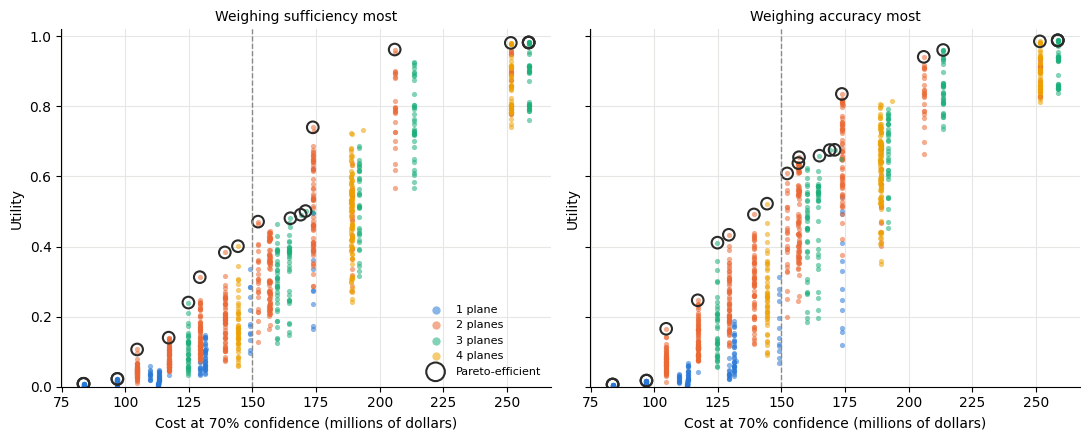

In [22]:
from tatc.tradespace import ExponentialUtility, LinearUtility, Utility

# the utility of the shares sampled sufficiently (linear) and accurately (concave: the first points matter most), for
# two stakeholders who weigh them differently
CURVES = {"sufficient": LinearUtility(0, 100), "accurate": ExponentialUtility(0, 100, risk=2)}
STAKEHOLDERS = {
    "sufficiency": Utility(CURVES, weights={"sufficient": 0.7, "accurate": 0.3}),
    "accuracy": Utility(CURVES, weights={"sufficient": 0.3, "accurate": 0.7}),
}
means = aggregate(
    refinement.results, {"sufficient": "sufficient", "accurate": "accurate", "cost p70": Quantile("cost", 0.7)}
).set_index("design")
means["description"] = [describe(values.loc[key]) for key in means.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
judged = {}
for ax, (name, utility) in zip(axes, STAKEHOLDERS.items()):
    judged[name] = means.assign(utility=utility(means))
    judged[name]["pareto"] = pareto_front(judged[name], {"utility": "max", "cost p70": "min"})
    legend = "lower right" if ax is axes[0] else None
    plot_designs(judged[name], "cost p70", "utility", by="planes", front="pareto", names=planes_name, legend=legend, ax=ax)
    ax.axvline(BUDGET, color=GRAY, lw=1, ls="--")
    ax.set(xlabel="Cost at 70% confidence (millions of dollars)", ylabel="Utility", ylim=(0, 1.02))
    ax.set_title(f"Weighing {name} most", fontsize=10)
    style_axes(ax, grid="both")
fig.tight_layout()
plt.show()

The stakeholders' fronts share most of their designs. Those efficient for one stakeholder and not the other:

In [23]:
# the designs efficient for one stakeholder and not the other
compared = means[["description", "satellites", "planes", "sufficient", "accurate", "cost p70"]].copy()
for name in STAKEHOLDERS:
    compared[f"utility ({name})"] = judged[name]["utility"]
    compared[f"efficient ({name})"] = judged[name]["pareto"]
print(f"{(compared['efficient (sufficiency)'] & compared['efficient (accuracy)']).sum()} designs are efficient for both")
compared[compared["efficient (sufficiency)"] != compared["efficient (accuracy)"]].sort_values("cost p70").round(2)

20 designs are efficient for both


,description,satellites,planes,sufficient,accurate,cost p70,utility (sufficiency),efficient (sufficiency),utility (accuracy),efficient (accuracy)
design,,,,,,,,,,
828c0027d01f,"800 km, 60 deg FOR, SSO: 1 at 12:00, 2 at 18:00",3,2,29.2,57.0,156.65,0.44,False,0.64,True
c576e2e2dbd1,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3,2,28.8,60.6,156.90,0.45,False,0.66,True
6ba50f2632cd,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,69.6,65.4,173.73,0.74,True,0.80,False
3690f1194419,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4,2,57.6,85.4,173.73,0.69,False,0.84,True
64cf6542c326,"800 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6,3,90.2,95.8,213.53,0.93,False,0.96,True


Within the budget, the stakeholders agree: every design efficient for either of them up to 150 million dollars is efficient for both, as more satellites in more planes buy both shares. Beyond the budget, they part. For 174 million dollars at 70% confidence, the stakeholder of sufficiency prefers four satellites in two Walker planes (70% of the points sufficiently sampled and 65% accurately), and the stakeholder of accuracy four in two sun-synchronous planes crossing at 09:00 and 15:00 (58% and 85%), whose planes spread the samples over the day. The stakeholder of accuracy also finds three satellites in two sun-synchronous planes efficient for 157 million (57 to 61% accurately sampled), and six in three Walker planes for 214 million (96%), which the stakeholder of sufficiency passes over. A utility is a metric of any statistic (such as `Quantile(utility, 0.1)`, the utility that a design exceeds in 90% of the replicates, for risks that the replicates draw) and so an objective of the searches as well; a multiplicative utility (`form="multiplicative"`) makes the shares complements, both of which a design must serve, or substitutes, either of which suffices.

## Account for Deployment

The shares of points sampled so far are those of each design's full constellation, as if its satellites flew for the whole mission. They are launched over months to years, during which fewer satellites sample the points. The launches of each design's deployment divide its mission into phases, in each of which a set of its satellites flies (`Deployment.phases`); each phase is evaluated over the same representative day with the observations of its satellites (`evaluate_phases`, which filters the observations of the full constellation, from the cache), and the phases are combined over the mission (`summarize_phases`): the mean of each share weighted by the duration of the phases, over the five years from the first launch (`sufficient mean`), and the time from the start of development until half of the points are sampled sufficiently (`sufficient time`, infinite if never).

The phased study evaluates the efficient designs of the first front (the most sufficient of each number of satellites and planes).

In [24]:
PHASED = ["sufficient", "sufficient mean", "sufficient time"]
leaders = front.sort_values("sufficient", ascending=False).drop_duplicates(["satellites", "planes"])
phased = make_study(phased=True).run([by_key[key] for key in leaders.design])
deployed = aggregate(phased, PHASED).set_index("design")[PHASED]
leaders = leaders.set_index("design")[["description", "satellites", "planes"]].join(deployed)
leaders["deployed"] = [SCHEDULE.plan(by_key[key].layout, kind=by_key[key].field_of_regard).deployed for key in leaders.index]
leaders["lost"] = leaders["sufficient"] - leaders["sufficient mean"]
leaders.sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "deployed", "sufficient", "sufficient mean", "lost", "sufficient time"]
].round(1)

,description,satellites,planes,deployed,sufficient,sufficient mean,lost,sufficient time
design,,,,,,,,
163120bf9590,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,3.2,3.2,0.0,inf
f7413b1f8466,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,3.5,16.6,16.6,0.0,inf
33b006848799,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,3.8,30.2,27.3,2.9,inf
d5d3fa915ca7,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,3.8,38.0,38.0,0.0,inf
1af5f2707be3,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,4.5,68.2,63.5,4.7,4.5
6ba50f2632cd,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,4.0,69.6,64.3,5.3,4.0
6bef11e40977,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,4.5,97.8,87.1,10.7,4.5


Deployment costs the designs of several planes or launches. Six satellites in two planes sample 98% of the points once deployed, but 87% on average over the mission, as the first plane flies alone for three quarters of a year while the second is produced, and they sample half of the points only 4.5 years after development starts, when the second plane is launched. Four satellites in one plane need two launches (of up to three satellites) half a year apart, and lose 5 points of their 68%; four satellites in two planes lose 5 points of their 70%, and two satellites in two planes 3 points of their 30%. The designs launched at once lose nothing. Over a five-year mission, the loss is the share of the mission before full deployment times the shortfall of the partial constellation: a shorter mission, slower production, or fewer launches a year would weigh deployment more, and could reorder the front.

Each phase is evaluated over the same day of July, as if the geometry of the satellites and the season were those of that day throughout the mission (quasi-static phases, see `evaluate_phases`). This misses the drift of the relative nodes of planes of different inclinations or altitudes (which precess at different rates), the drift of the local times of planes that are not sun-synchronous, and seasons. Here, the planes of each design share an altitude and an inclination, which keeps their relative geometry, and the shares do not depend on the sun, so the day should represent the mission. Drawing the start of the day for each replicate over a year (the `epoch` of the design space, which `Observations` and the metrics read, as an `Uncertain` parameter) averages the replicates over the drift and the seasons, at the cost of analyzing the satellites again for each day:

In [25]:
# the leading designs, with the day of the analysis drawn for each replicate over a year
EPOCH = Uncertain(lambda rng: START + timedelta(days=float(rng.uniform(0, 365))))
epoch_space = DesignSpace(**{**space.children, "epoch": EPOCH}, constraints=space.constraints)
year = make_study(phased=True, design_space=epoch_space, label="over a year").run(
    [epoch_space.design(by_key[key].decisions) for key in leaders.index]
)
MEANS = ["sufficient mean", "accurate mean"]
over_year = summarize(year, MEANS, design_columns=[]).set_index("design")
july = aggregate(phased, MEANS).set_index("design")[MEANS]
leaders[["description", "satellites", "planes"]].join(july.add_suffix(" (July)")).join(
    over_year[[*MEANS, *(f"{m} sem" for m in MEANS)]].add_suffix(" (year)")
).sort_values(["satellites", "planes"]).round(1)

,description,satellites,planes,sufficient mean (July),accurate mean (July),sufficient mean (year),accurate mean (year),sufficient mean sem (year),accurate mean sem (year)
design,,,,,,,,,
163120bf9590,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,2.8,3.2,3.0,0.7,0.6
f7413b1f8466,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.6,4.0,16.2,2.0,1.0,0.7
33b006848799,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,27.3,30.9,25.8,28.8,1.6,1.6
d5d3fa915ca7,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.0,11.4,37.8,9.8,0.5,0.7
1af5f2707be3,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,63.5,24.5,61.7,22.5,1.8,0.8
6ba50f2632cd,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,64.3,59.3,62.1,58.0,1.5,1.3
6bef11e40977,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,87.1,71.1,86.7,70.3,0.2,0.8


Over the year, the means of the leading designs are within 2.2 points of those of the day in July (and within three standard errors of the year's means), most a little lower: the one day represents the mission well here. A constellation of planes at different altitudes or inclinations, metrics that depend on daylight, or a field that varies with the seasons would call for drawing the epoch. The phases also assume that a satellite operates until it fails or is replaced: a design life does not retire a satellite whose replacement is not launched, and a planned replacement whose launch fails is not flown again (see `DeploymentSchedule`).

## Stage the Deployment

A deployment need not commit to every plane at once. A stage of a deployment (`Stage`) is a set of planes produced and launched only if a rule decides to, at times during the mission, from what it knows then (a `Decision`: the satellites operating and the history so far) and from the values of the design, such as its uncertain parameters and its scenario. A stage that is not deployed is neither produced, launched, nor paid for, so that a staged deployment is an option: it saves the cost of a stage where the mission does not need it, and loses what deferring the stage costs where it does (as above, the capability of the satellites not yet launched). Whether and how to stage is a decision of each design (here, a value `staging` of the design space), and the `stages` of a `MissionPlan` are a function of the design.

Here, the robust design of four satellites across the fields of the scenarios above (two sun-synchronous planes of two) deploys its second plane at once, never, or only if the field turns out to vary within hours (to decorrelate within 6 hours), as decided at the first launch or a year later. Each staging is evaluated in each field by the phases of its deployment: the mean share of points accurately sampled over the mission, and the present cost:

In [26]:
import dataclasses

from tatc.tradespace import Stage

STAGING = ["at once", "first plane", "decided at launch", "decided a year later"]
staging_space = DesignSpace(**space.children, staging=Categorical(STAGING), constraints=space.constraints)


def stages(d):
    """The stages of a design's deployment: its second plane deployed with the first (at once), never (first plane),
    or if the field decorrelates within 6 hours, as decided at the first launch or a year later."""
    if d.staging == "at once":
        return []
    if d.staging == "first plane":
        return [Stage(1, 0.0, lambda decision: False)]
    when = 0.0 if d.staging == "decided at launch" else 1.0
    return [Stage(1, when, lambda decision: d.decorrelation_time < timedelta(hours=6))]


# the robust design of four satellites across the fields, with each staging of its deployment, in each field
four = by_key[robust_design[4]]
staged = make_study(
    phased=True,
    scenarios=FIELDS,
    design_space=staging_space,
    plan=dataclasses.replace(PLAN, stages=stages),
    label="staged",
).run([staging_space.design({**four.decisions, "staging": option}) for option in STAGING])
staged.groupby(["staging", "scenario"], sort=False)[["accurate mean", "cost present"]].mean().unstack("scenario").round(1)

accurate mean                  cost present          \
scenario                    1 hour 3 hours 12 hours       1 hour 3 hours   
staging                                                                    
at once                       62.6    77.9     91.0        156.4   156.4   
first plane                    4.8    10.0     73.0        118.8   118.8   
decided at launch             62.6    77.9     73.0        156.4   156.4   
decided a year later          49.7    62.8     73.0        154.5   154.5   

                               
scenario             12 hours  
staging                        
at once                 156.4  
first plane             118.8  
decided at launch       118.8  
decided a year later    118.8

Deciding at the first launch is worth the most. Where the field varies within hours, the second plane is produced and launched as if it were deployed at once (63% and 78% of the points accurately sampled on average over the mission, for 156 million dollars), and where it varies slowly, it is not, which saves 38 million dollars (24%) for 18 points of the mean (73% against 91%): a trade that the rule makes, and that a mission might not. Deciding a year later costs the fields that need the second plane 13 to 15 points of the mean (50% and 63%), as the first plane flies alone for a year more, and saves only 2 million dollars, by discounting the later production. The value of the option is that of knowing the need when it is exercised: the earlier the field is known, the more staging saves at less loss. A rule may decide on anything known by then, such as the satellites still operating (see `Decision`), for a reserve plane launched only if satellites fail.

## Screen Designs with a Cheaper Analysis

Evaluating every design is affordable here, but not for larger spaces or longer analyses. `screen` evaluates every design with a cheap study, keeps the best (whole fronts, until it keeps at least `keep` of them), and evaluates only those with the full study. A cheap study ranks designs less exactly, so a `tolerance` of an objective keeps designs that are within it of the front of the cheap study.

The cheap study must rank designs as the full study would. Here, the screening study analyzes one replicate, rather than five, over a shorter period, with the threshold of sufficient sampling scaled to the period: 12 hours with two observations, or 6 hours with one. The table compares each screening's front with the true front (how many of its efficient designs it keeps, and its hypervolume), and its cost (the satellites analyzed times the days of their analyses) with that of evaluating every design.

In [27]:
from tatc.tradespace import screen

full_cost = results.satellites.sum() * DURATION / timedelta(days=1)  # satellite-days of analysis
true_front = set(summary.design[summary.pareto])
screenings = []
for hours, keep, tolerance in [(12, 0.05, None), (12, 0.1, 5.0), (6, 0.05, None), (6, 0.2, None)]:
    screening = screen(
        designs,
        [make_study(timedelta(hours=hours), replicates=1), make_study()],
        OBJECTIVES,
        keep=keep,
        tolerance=None if tolerance is None else {"sufficient": tolerance},
    )
    # the satellite-days of the analyses of each stage
    days = screening.results.stage.map({0: hours / 24, 1: DURATION / timedelta(days=1)})
    screenings.append(
        {
            "screening study": f"{hours} h, 1 replicate",
            "keep (%)": 100 * keep,
            "tolerance (%)": tolerance,
            "designs kept": len(screening.designs),
            "efficient designs kept": f"{len(true_front & {d.key for d in screening.designs})} of {len(true_front)}",
            "hypervolume (% of true front)": 100 * hypervolume(screening.final, OBJECTIVES, REFERENCE) / exact_hypervolume,
            "cost (% of every design)": 100 * (screening.results.satellites * days).sum() / full_cost,
        }
    )
pd.DataFrame(screenings).round(1)

,screening study,keep (%),tolerance (%),designs kept,efficient designs kept,hypervolume (% of true front),cost (% of every design)
0,"12 h, 1 replicate",5.0,NaN,74,4 of 7,98.8,16.9
1,"12 h, 1 replicate",10.0,5.0,248,7 of 7,100.0,29.2
2,"6 h, 1 replicate",5.0,NaN,62,1 of 7,83.0,10.6
3,"6 h, 1 replicate",20.0,NaN,231,5 of 7,96.6,25.1


The 12-hour screening study ranks designs nearly as the full study does. Keeping the best 5% of the designs finds a front with 99% of the hypervolume of the true front at 17% of the cost of evaluating every design, although it misses three of the seven efficient designs, whose places designs with nearly the same objectives take. Keeping 10%, with a tolerance of 5 percentage points, keeps every efficient design at 29% of the cost.

The 6-hour screening study is cheaper, but ranks designs differently: one observation of a point in 6 hours separates designs less than four observations in a day do. Keeping 5% of the designs keeps only one of the seven efficient ones (83% of the hypervolume), and keeping 20% still misses two of them (97% of the hypervolume) at 25% of the cost, nearly as much as the 12-hour study that keeps them all. How many designs to keep depends on how well the cheap study ranks designs, which is worth checking on a sample of designs evaluated with both studies before screening a larger space.

## Search with Optimizers

Larger design spaces cannot be enumerated or even screened, and an optimizer searches them for efficient designs instead. `optimize_optuna` suggests designs with Optuna's trials, which search the hierarchical design space directly (`DesignSpace.suggest`), and records the violation of the constraint of each infeasible design, which Optuna's samplers use to prefer feasible designs. `optimize_pymoo` searches the unit hypercube that encodes the design space (`DesignSpace.decode`) with a pymoo algorithm, which eliminates the proposals of designs proposed or evaluated before: many points of the hypercube decode to the same design (those in the same level of each variable, or that differ only in the variables of a branch not chosen), which pymoo's own elimination of equal points does not see. Both evaluate each design once, however often it is proposed, and evaluate the designs proposed together in parallel. A search chooses its front from one evaluation of each design, which favors designs whose replicates were lucky: its designs and results (a `Search`) are refined and confirmed as above.

Each search below is given a budget of about 200 proposals, and is compared with a Latin hypercube sample of 200 designs (`DesignSpace.sample`). The designs evaluated (and the analyses of their satellites) are those of the evaluation of every design above, so they are retrieved from the cache.

In [28]:
import optuna
from pymoo.algorithms.moo.nsga2 import NSGA2

from tatc.tradespace import hypervolume_progress, optimize_optuna, optimize_pymoo

optuna.logging.set_verbosity(optuna.logging.WARNING)
BUDGET = 200
study = make_study()
searches = {}
searches["Optuna (NSGA-II)"] = optimize_optuna(
    study,
    OBJECTIVES,
    n_trials=BUDGET,
    sampler=optuna.samplers.NSGAIISampler(population_size=20, seed=1),
    batch_size=20,
).results
searches["pymoo (NSGA-II)"] = optimize_pymoo(
    study, OBJECTIVES, NSGA2(pop_size=20), ("n_gen", BUDGET // 20), seed=1
).results
searches["Latin hypercube sample"] = study.run(space.sample(BUDGET, method="lhs", seed=1))

# the hypervolume (% of the true front's) of the designs evaluated, as designs are evaluated
progress = {
    name: 100 * hypervolume_progress(search_results, OBJECTIVES, REFERENCE) / exact_hypervolume
    for name, search_results in searches.items()
}
pd.DataFrame(
    {
        name: {
            "designs evaluated": search_results.design.nunique(),
            "hypervolume (% of true front)": progress[name].iloc[-1],
        }
        for name, search_results in searches.items()
    }
).T.round(1)

,designs evaluated,hypervolume (% of true front)
Optuna (NSGA-II),143.0,92.1
pymoo (NSGA-II),166.0,100.0
Latin hypercube sample,176.0,79.3


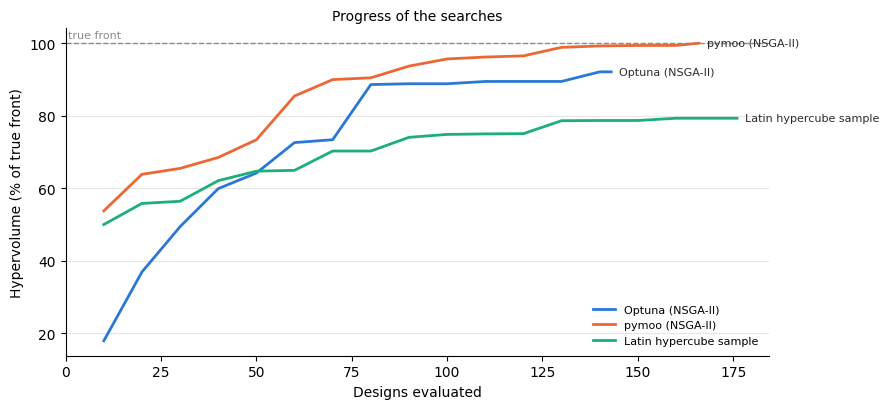

In [29]:
from tatc.tradespace import plot_progress

ax = plot_progress(progress)
ax.axhline(100, color=GRAY, lw=1, ls="--")
ax.annotate("true front", (0, 100), xytext=(2, 4), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(ylabel="Hypervolume (% of true front)")
ax.set_title("Progress of the searches", fontsize=10)
ax.figure.tight_layout()
plt.show()

Both optimizers find more of the hypervolume than a Latin hypercube sample of as many designs. Optuna (NSGA-II, searching the hierarchical space directly) finds 92% of the hypervolume of the true front with 143 designs, 13% of the space. pymoo (NSGA-II, searching the encoded space) finds all of it with 166 designs: it proposes no design twice, and its other 34 proposals violate the constraint on the number of satellites (without eliminating duplicates by design, its 200 proposals encoded only 75 designs, which found 88%). The sample finds 79% with 176 designs. The searches stop at their budget of proposals, not at convergence: a larger budget, or screening, would bring Optuna's closer to the true front. Their results also depend on their seeds (over eight seeds, pymoo's search finds 88 to 100% of the hypervolume, 96.5% on average), so compare several seeds before relying on one.

## Summary

* A `DesignSpace` declares a hierarchical trade space, with choices between alternatives (`Choice`), repeated elements such as orbit planes (`Repeat`), bounds that depend on other variables, constraints that measure their violation, and uncertain parameters (`Uncertain`) drawn for each replicate. Building blocks declare common constellation layouts (`walker_space` and `sso_planes_space`) and build their satellites with instruments or entries of the instrument catalog (`build_constellation`).
* An `ObservationStudy` (a `Study` of the observations of `Targets`, with a `MissionPlan` of deployment and costs, and `Failures`) evaluates designs in replicates (here, of points of a randomly oriented lattice, `generate_points_rotated_lattice`, which vary less between replicates than random points), in parallel, with a cache of `Observations` that analyzes each distinct satellite once and a `ResultStore` that keeps its evaluations (by the fingerprint of the study, which describes its targets and the code of TAT-C it uses, so that a changed study evaluates its designs again, and says why). Every design of a space of about a thousand designs can be evaluated in minutes.
* Statistical sufficiency is measured by the sampling error of the statistic that observations estimate (`tatc.analysis.estimate_sampling_error`), which counts of samples overstate when samples cluster in time, as they do in a single plane; revisit statistics and local time coverage explain it.
* The front of the means of the replicates is uncertain: `pareto_probability` finds the designs whose efficiency the replicates settle, and those that are equally good candidates, and `refine` adds replicates only to the latter, with a tolerance of differences that do not matter. `confirm` evaluates the selected designs with new replicates, which removes the optimism of selecting the best of many nearly equal designs.
* Statistics other than means (such as a `Quantile` or the `Probability` of meeting a threshold) state how reliably a design performs, and `Requirement`s on them are output constraints. Simulated missions (`Deployment.simulate`) draw the failures of satellites and launches from lives whose failure rates vary over the lifecycle (`FailureModel`), and restore them or not (`RestorationPolicy`, by spares in orbit or on the ground, or by producing new ones), for both the cost and the capability of each policy (exactly, without sampling, for missions that do not restore failed satellites: `expected_missions`); the policy is a decision of each design (`policy_space`, configured by `configure`), on the front with the design. `sensitivity` finds the design variables that drive each objective, and `attribute_variance` the uncertain parameters that spread the replicates of each design (by drawing each again with the others held): here, the sample of points spreads the mean shares and the histories of failures their worst 10%, which says what would sharpen each, and the growth of costs spreads the costs of designs alike, so that it cancels in their differences (`Attribution.differences`) and does not change their order.
* The `scenarios` of a study compare designs under conditions rather than averaging over them (here, fields of different decorrelation times, a value of the design space): criteria `by` the scenario give the front of each, and `robustness` the share of the scenarios in which each design is efficient (its Pareto trace) and its regret in each, whose least maximum is a robust choice (here, six satellites efficient in no field but never half a point behind the best).
* `screen` evaluates every design with a cheap study and the best with the full one, which finds the front at a fraction of the cost if the cheap study ranks designs as the full one does.
* A `Utility` weighs metrics by a stakeholder's preferences (a single-attribute utility of each, combined by weights) into one objective against cost, and is a metric of any statistic (its mean is the expected utility): here, stakeholders who weigh sufficiency or accuracy most agree within the budget and part beyond it.
* A `DeploymentSchedule` plans each design's deployment from rates of production and launch, which dates its costs and divides its mission into phases of the satellites that fly, evaluated with the observations of the full constellation (over one day, which an epoch drawn for each replicate shows to represent the mission here) for the mean capability over the mission and the time until a requirement is met.
* A `Stage` of a deployment is produced and launched only if a rule decides to, from what is known then (a `Decision`) and the values of the design: an option whose value the analyses of a study measure (here, deciding at the first launch whether the field needs a second plane saves 38 million dollars where it does not, at no loss where it does, and deciding a year later loses 13 to 15 points of the mean where it does).
* A `CostModel` estimates the life-cycle cost of each deployment from the costs of its satellites, launches, and operations (given by the study), with uncertain growth whose quantiles give the cost at a confidence level, as an objective or a requirement in place of the numbers of satellites and planes.
* `optimize_optuna` and `optimize_pymoo` search spaces too large to enumerate, and find most of the front with a fraction of the designs (`hypervolume_progress`), pymoo's proposing no design twice (by design, not by point of the encoded space).
* `plot_designs` and `plot_progress` plot the designs, with the efficient ones ringed, and the progress of searches.

The sampling error here is that of a model of the field (an exponential correlation in time with a decorrelation time of 3 hours); with a simulation of the field (a nature run), `tatc.analysis.sample_field` and `compare_sampled_means` measure it directly. The costs are illustrative, and the numbers of satellites and planes, proxies of cost in the other sections. The uncertainties are those of the sample of points and the failures of satellites; others (such as the phase of the satellites or the period of the analysis) are further `Uncertain` parameters of the design space.